# Screen a batch of network traffic for intrusions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OliverHennhoefer/nonconform/blob/main/examples/batch_screening.ipynb)

A thousand new connections arrived and an analyst can review a short list. The
list should be worth reading: on average, at most 10% of what it contains should
be normal traffic. That is what `select(x, alpha=0.1)` is for.

The data is the HTTP subset of KDD Cup 99 from `oddball`: about 280,000 normal
connections for reference, and a test batch of 1,000 connections of which 10%
are attacks.

In [1]:
# On Colab or a fresh environment, install what this notebook needs.
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("oddball") is None:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "nonconform[data]",
            "matplotlib",
        ],
        check=True,
    )

In [2]:
import numpy as np
from oddball import Dataset, load
from sklearn.ensemble import IsolationForest

from nonconform import ConformalDetector, Split

x_reference, x_batch, y_batch = load(Dataset.HTTP, setup=True, seed=0)
print(f"Reference rows: {len(x_reference):,}")
print(f"Batch rows: {len(x_batch):,}, of which attacks: {int(y_batch.sum())}")

Reference rows: 282,643
Batch rows: 1,000, of which attacks: 100


## Size the calibration set for the batch

The smallest p-value a detector can produce is `1 / (n_calib + 1)`. The
Benjamini-Hochberg procedure behind `select()` flags a single anomaly on its own
only if its p-value is at or below `alpha / batch_size`. With fewer calibration
scores it can still flag a group of anomalies that all beat every calibration
score, but not a lone one. So the rule of thumb is

```text
n_calib >= batch_size / alpha
```

Here that is `1,000 / 0.1 = 10,000`. The cell below compares that with a
calibration set of 1,000.

In [3]:
alpha = 0.1
rule_n_calib = int(np.ceil(len(x_batch) / alpha))

results = {}
for n_calib in (1_000, rule_n_calib):
    detector = ConformalDetector(
        detector=IsolationForest(random_state=0),
        strategy=Split(n_calib=n_calib),
        score_polarity="auto",
        seed=0,
    ).fit(x_reference)
    flagged = detector.select(x_batch, alpha=alpha)
    results[n_calib] = (flagged, detector.last_result.p_values)

    n_flagged = int(flagged.sum())
    false_share = (flagged & (y_batch == 0)).sum() / max(n_flagged, 1)
    found = (flagged & (y_batch == 1)).sum() / y_batch.sum()
    print(
        f"n_calib={n_calib:>6,}: flagged {n_flagged:>3}, "
        f"false share {false_share:.0%}, attacks found {found:.0%}"
    )

select() made no discoveries. With 1000 calibration scores, classical conformal p-values cannot fall below 1/1001 = 0.000999, but a single BH discovery among m = 1000 tests needs p <= alpha/m = 0.0001. Any discovery requires at least 10 test points that jointly attain that minimum. Use at least 9999 calibration scores, or smaller test batches, so that a single anomaly can be discovered.


n_calib= 1,000: flagged   0, false share 0%, attacks found 0%


n_calib=10,000: flagged 114, false share 13%, attacks found 99%


## All or nothing

Each panel sorts the batch's p-values. Benjamini-Hochberg flags every point up
to the last one that falls below the dashed line `rank * alpha / batch_size`.
The attacks are near-duplicates, so they share a handful of p-values and are
flagged together or not at all. They are 10% of the batch, so their shared
p-value must reach the line at rank 100, which is 0.01: they must score above
all but 1% of the calibration points. With 1,000 calibration scores they sit
near 0.02. With 10,000, this fit puts them near 0.004.

That depends on the fitted forest as much as on the calibration size. Change
`seed` and rerun: some fits return an empty list at 10,000 and a full one at
1,000. Over 30 seeds, an empty list came up 8 times at 1,000 and 2 times at
10,000. A larger calibration set makes an empty list rarer, but
does not rule one out when the anomalies score only slightly above normal
traffic.

In [4]:
import matplotlib.pyplot as plt

NORMAL, ANOMALY, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#8a8984"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.8,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "font.size": 10,
    }
)

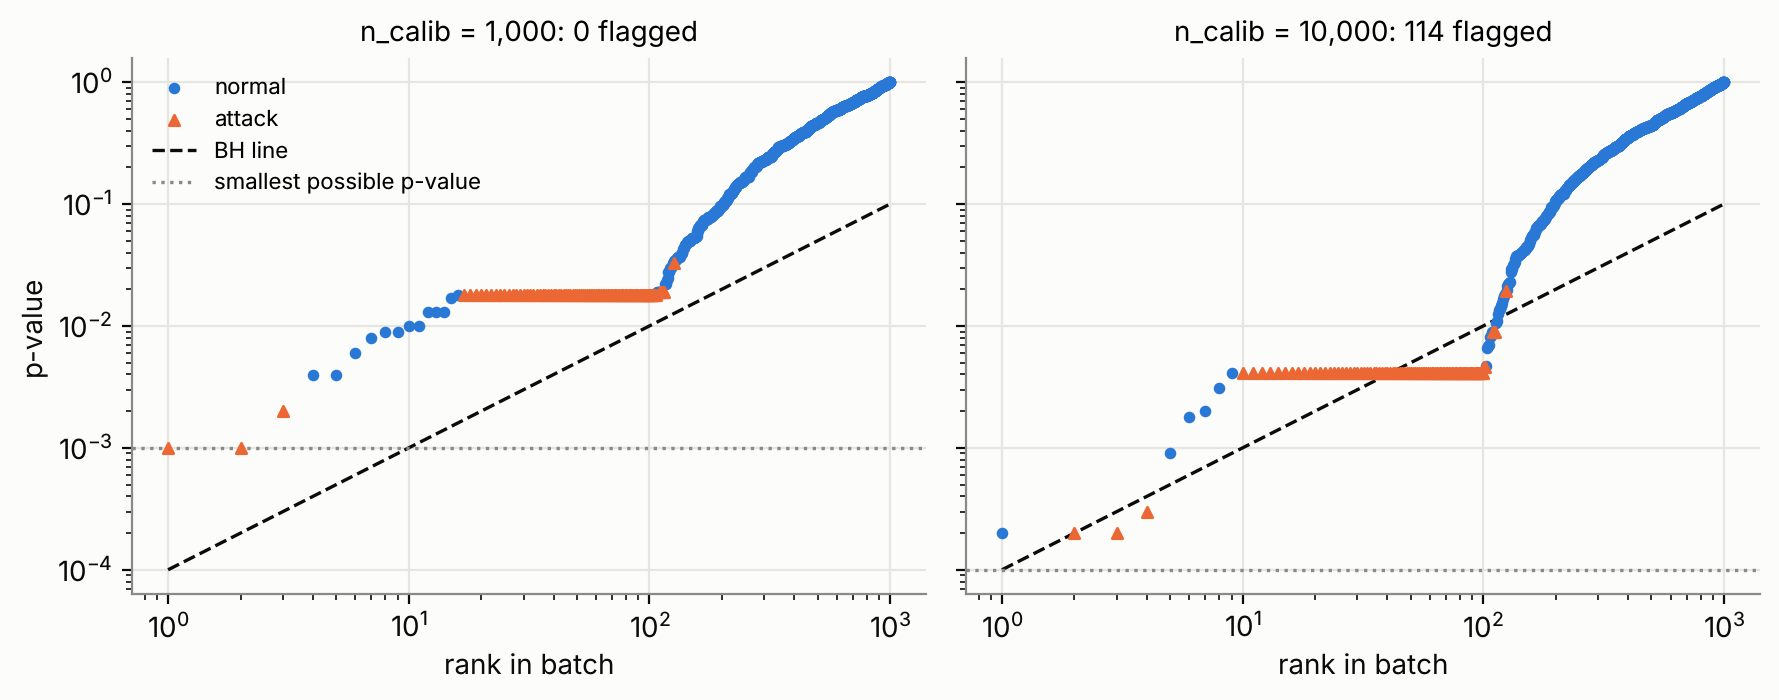

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
ranks = np.arange(1, len(x_batch) + 1)
for ax, (n_calib, (flagged, p_values)) in zip(axes, results.items(), strict=True):
    order = np.argsort(p_values, kind="stable")
    is_attack = y_batch[order] == 1
    ax.scatter(
        ranks[~is_attack],
        p_values[order][~is_attack],
        s=10,
        color=NORMAL,
        marker="o",
        label="normal",
        zorder=3,
    )
    ax.scatter(
        ranks[is_attack],
        p_values[order][is_attack],
        s=14,
        color=ANOMALY,
        marker="^",
        label="attack",
        zorder=3,
    )
    ax.plot(
        ranks, ranks * alpha / len(x_batch), color=INK, lw=1.2, ls="--", label="BH line"
    )
    ax.axhline(
        1 / (n_calib + 1),
        color=MUTED,
        lw=1.2,
        ls=":",
        label="smallest possible p-value",
    )
    ax.set(
        xscale="log",
        yscale="log",
        xlabel="rank in batch",
        title=f"n_calib = {n_calib:,}: {int(flagged.sum())} flagged",
    )
    ax.title.set_size(10)
axes[0].set_ylabel("p-value")
axes[0].legend(loc="upper left", fontsize=8)
fig.tight_layout()
plt.show()

## What to take away

- `alpha` is the target share of false flags among the flagged points, averaged
  over repeated batches. It is not a score threshold.
- An empty list is an answer: the evidence was not strong enough to back the
  promise. If the calibration set is below `batch_size / alpha`, enlarge it
  first. If you need a fixed threshold instead of a list, see the
  `false_alarm_threshold.ipynb` notebook.
- The guarantee rests on the reference data being clean and exchangeable with
  the normal points in the batch. See *Assumptions and guarantees* in the docs.